Import Libraries

In [41]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import precision_recall_fscore_support
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from collections import Counter
import matplotlib.pyplot as plt
import re
from bs4 import BeautifulSoup
import random

Random Forest Implementation

In [42]:
class RandomForest:
    def __init__(self, n_trees=10, max_depth=None, sample_size=0.8):
        self.n_trees = n_trees
        self.max_depth = max_depth
        self.sample_size = sample_size
        self.trees = []

    def fit(self, X, y):
        for _ in range(self.n_trees):
            indices = np.random.choice(X.shape[0], int(self.sample_size * X.shape[0]), replace=True)
            X_sample, y_sample = X[indices], y[indices]
            tree = DecisionTreeClassifier(max_depth=self.max_depth, random_state=42)
            tree.fit(X_sample, y_sample)
            self.trees.append(tree)

    def predict(self, X):
        tree_preds = np.array([tree.predict(X) for tree in self.trees])
        return np.array([Counter(tree_preds[:, i]).most_common(1)[0][0] for i in range(X.shape[0])])


Loading the data

In [43]:
file_path = '/Users/pckiousis/Downloads/IMDB Dataset.csv'
imdb_data = pd.read_csv(file_path)
imdb_data['sentiment'] = imdb_data['sentiment'].map({'positive': 1, 'negative': 0})

Clean the text

In [44]:

def clean_text(text):
    try:
        text = BeautifulSoup(text, "html.parser").get_text()
    except Exception:
        text = str(text)
    text = re.sub(r'[^a-zA-Z\s]', '', text).lower()
    return text

imdb_data['cleaned_review'] = imdb_data['review'].apply(clean_text)


/var/folders/tx/6xkjd5sj2939z8hlssc2tdhr0000gp/T/ipykernel_57643/1010727831.py:3: MarkupResemblesLocatorWarning: The input looks more like a filename than markup. You may want to open this file and pass the filehandle into Beautiful Soup.
  text = BeautifulSoup(text, "html.parser").get_text()


Counting the word frequency in the text

In [45]:
subset_size = 5000
imdb_subset = imdb_data.sample(n=subset_size, random_state=42)

vectorizer_full = CountVectorizer(binary=True, stop_words='english')
X_full_counts = vectorizer_full.fit_transform(imdb_subset['cleaned_review'])
word_freq = np.asarray((X_full_counts > 0).sum(axis=0)).flatten()


Removing n most frequent and k most rare words

In [46]:
n = 100
k = 100
valid_indices = np.argsort(word_freq)[k:len(word_freq) - n]
X_filtered_counts = X_full_counts[:, valid_indices]
filtered_vocab = np.array(vectorizer_full.get_feature_names_out())[valid_indices]


Selecting m words with the highest IG

In [47]:
m = 1000
mutual_info = mutual_info_classif(X_filtered_counts, imdb_subset['sentiment'], discrete_features=True)
top_m_indices = np.argsort(mutual_info)[-m:]
X_final_counts = X_filtered_counts[:, top_m_indices]
final_vocab = filtered_vocab[top_m_indices]

Splitting the data into training , development and test sets and converting labels to numpy arrays

In [48]:
X_train, X_temp, y_train, y_temp = train_test_split(X_final_counts, imdb_subset['sentiment'], test_size=0.4, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

y_train = y_train.to_numpy()
y_temp = y_temp.to_numpy()
y_dev = y_dev.to_numpy()
y_test = y_test.to_numpy()

Initializing the Random Forest

In [73]:
rf_model = RandomForest(n_trees=1000, max_depth=20, sample_size=1.0) #1000 trees for stabilized predictions and variance in the data

Training Random Forest model with learning curve evaluation ΟΝ negative(labels[0]) category

In [74]:
train_sizes = [100, 500, 1000, X_train.shape[0]]
precision_dev, recall_dev, f1_dev = [], [], []
precision_train, recall_train, f1_train = [], [], []

for size in train_sizes:
    X_train_subset = X_train[:size].toarray()
    y_train_subset = y_train[:size]

    rf_model.fit(X_train_subset, y_train_subset)
    
    y_pred_dev = rf_model.predict(X_dev.toarray())
    y_pred_train = rf_model.predict(X_train_subset)
    
    precision, recall, f1, _ = precision_recall_fscore_support(y_dev, y_pred_dev, average=None, labels=[0])
    precision_dev.append(precision[0])
    recall_dev.append(recall[0])
    f1_dev.append(f1[0])
    
    precision, recall, f1, _ = precision_recall_fscore_support(y_train_subset, y_pred_train, average=None, labels=[0])
    precision_train.append(precision[0])
    recall_train.append(recall[0])
    f1_train.append(f1[0])


Plotting the results

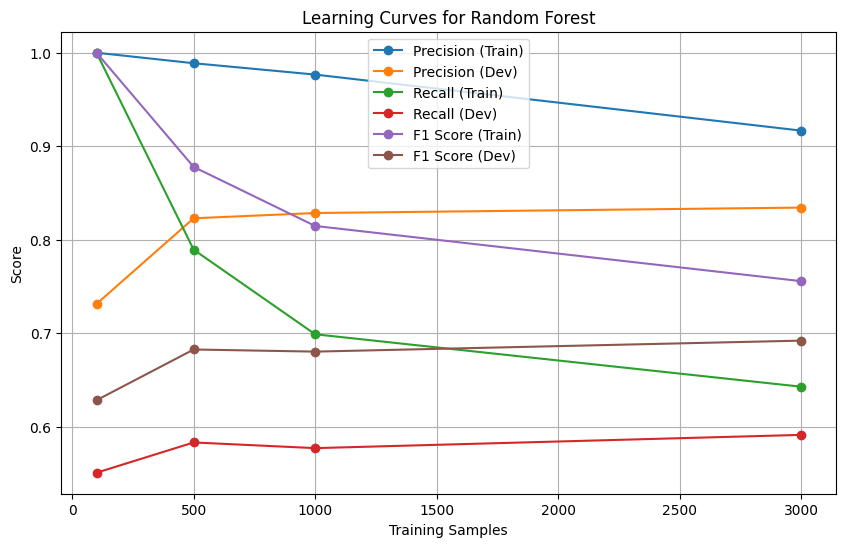

In [75]:
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, precision_train, label="Precision (Train)", marker='o')
plt.plot(train_sizes, precision_dev, label="Precision (Dev)", marker='o')
plt.plot(train_sizes, recall_train, label="Recall (Train)", marker='o')
plt.plot(train_sizes, recall_dev, label="Recall (Dev)", marker='o')
plt.plot(train_sizes, f1_train, label="F1 Score (Train)", marker='o')
plt.plot(train_sizes, f1_dev, label="F1 Score (Dev)", marker='o')
plt.xlabel("Training Samples")
plt.ylabel("Score")
plt.title("Learning Curves for Random Forest")
plt.legend()
plt.grid()
plt.show()

Evaluating on test data

In [76]:
y_pred_test = rf_model.predict(X_test.toarray())
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_test, average=None, labels=[0, 1])
micro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='micro')
macro_avg = precision_recall_fscore_support(y_test, y_pred_test, average='macro')

print("\nTest Data Precision, Recall, F1 Scores:")
print(f"Class 0: Precision: {precision[0]:.2f}, Recall: {recall[0]:.2f}, F1: {f1[0]:.2f}")
print(f"Class 1: Precision: {precision[1]:.2f}, Recall: {recall[1]:.2f}, F1: {f1[1]:.2f}")
print(f"Micro Average: Precision: {micro_avg[0]:.2f}, Recall: {micro_avg[1]:.2f}, F1: {micro_avg[2]:.2f}")
print(f"Macro Average: Precision: {macro_avg[0]:.2f}, Recall: {macro_avg[1]:.2f}, F1: {macro_avg[2]:.2f}")



Test Data Precision, Recall, F1 Scores:
Class 0: Precision: 0.85, Recall: 0.61, F1: 0.71
Class 1: Precision: 0.68, Recall: 0.88, F1: 0.77
Micro Average: Precision: 0.74, Recall: 0.74, F1: 0.74
Macro Average: Precision: 0.76, Recall: 0.75, F1: 0.74
